### 10차시 교안 이미지: 지난 차시 그래프 2×2

* 교안 "지금까지 그린 그래프로 다시 보기"에 넣을 그림을 만든다.
* 칸마다 위에 질문 한 줄과 유형 이름표를 단다.
  * 메뉴별 총판매량 막대 · 수면 시간 히스토그램 · 공부 시간과 시험 점수 산점도 · 월별 평균 손님 수 선 그래프
* 결과: 이 노트북과 같은 폴더에 `viz10_recap_2x2.png`
* 데이터는 `../data/`(students.csv, cafe_sales.csv)를 읽는다. Colab에서 쓸 때는 `DATA` 경로만 바꾼다.

In [1]:
# 표는 pandas, 그래프는 plt로 다룬다
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 데이터 폴더 경로 (Colab이면 'data'로 바꾼다)
DATA = '../data'

# 나눔고딕을 찾아 등록한다: 제작 PC(_tools/NanumGothic.ttf) 또는 Colab(fonts-nanum)
for path in ['../_tools/NanumGothic.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    if os.path.exists(path):
        font_manager.fontManager.addfont(path)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
# 두 CSV를 읽는다
students = pd.read_csv(f'{DATA}/students.csv')
cafe = pd.read_csv(f'{DATA}/cafe_sales.csv', parse_dates=['date'])

# 메뉴별 총판매량
menu_total = cafe[['americano', 'latte', 'ade', 'tea']].sum()
menu_total.index = ['아메리카노', '라떼', '에이드', '차']
# 빈 값을 뺀 수면 시간
sleep = students['sleep_hours'].dropna()
# 월별 평균 손님 수
customers_by_month = cafe.groupby('year_month')['customers'].mean().round(2)

print(menu_total.to_dict())
print(len(sleep), customers_by_month.idxmax(), customers_by_month.idxmin())

{'아메리카노': 40866, '라떼': 22611, '에이드': 20523, '차': 9770}
285 2025-04 2026-02


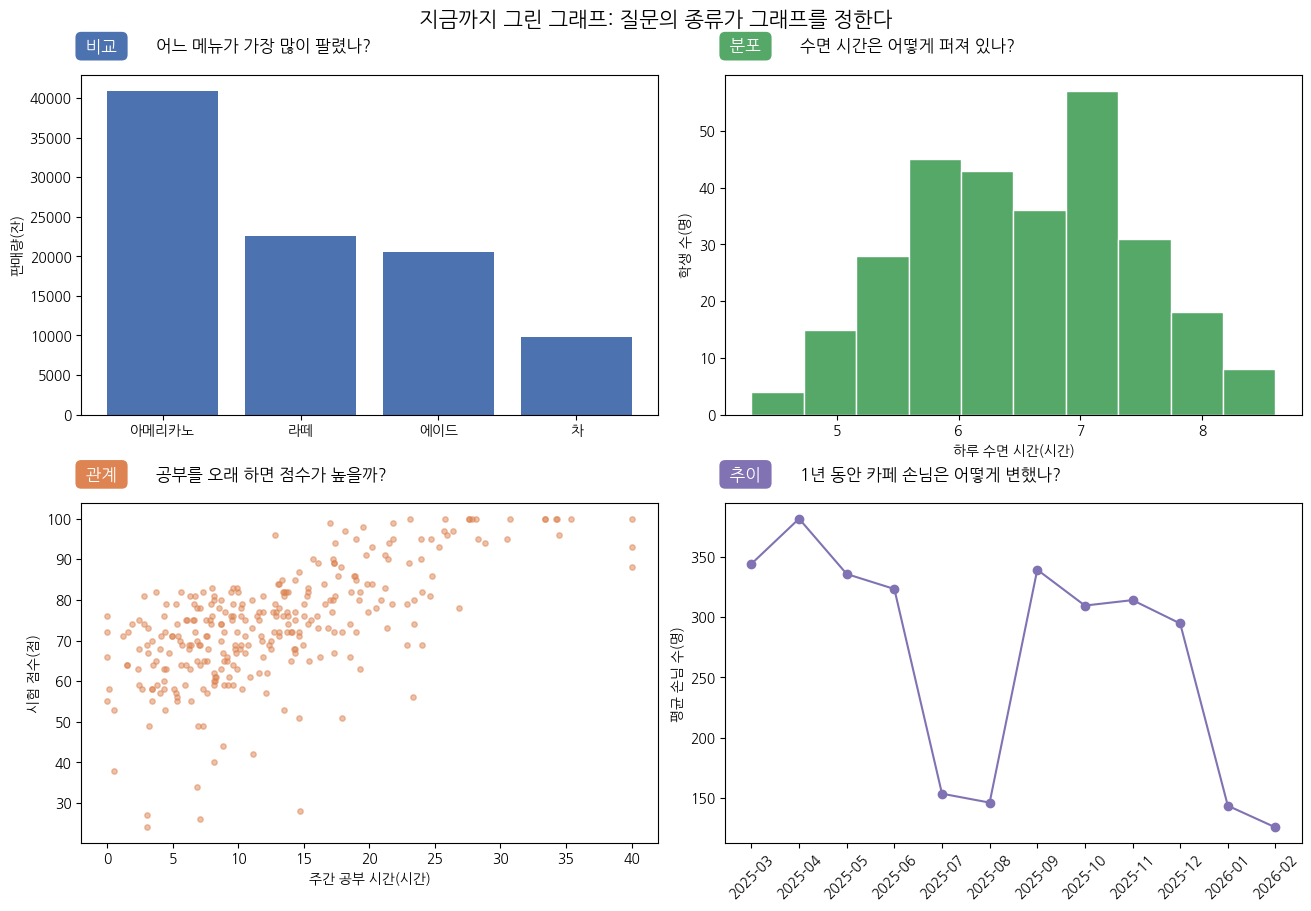

In [3]:
# 유형 이름표 색: 비교 · 분포 · 관계 · 추이
TAG_COLOR = {'비교': '#4C72B0', '분포': '#55A868', '관계': '#DD8452', '추이': '#8172B3'}


def label(ax, kind, question):
    """칸 왼쪽 위에 유형 이름표를, 그 오른쪽에 질문 한 줄을 단다."""
    ax.text(0, 1.06, f' {kind} ', transform=ax.transAxes, fontsize=12, fontweight='bold',
            color='white', va='bottom', ha='left',
            bbox=dict(boxstyle='round,pad=0.35', fc=TAG_COLOR[kind], ec='none'))
    ax.text(0.13, 1.06, question, transform=ax.transAxes, fontsize=12,
            va='bottom', ha='left')


fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')

# 왼쪽 위: 비교 - 메뉴별 총판매량 막대
ax = axes[0, 0]
ax.bar(menu_total.index, menu_total.values, color='#4C72B0')
ax.set_ylabel('판매량(잔)')
label(ax, '비교', '어느 메뉴가 가장 많이 팔렸나?')

# 오른쪽 위: 분포 - 수면 시간 히스토그램
ax = axes[0, 1]
ax.hist(sleep, color='#55A868', edgecolor='white')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
label(ax, '분포', '수면 시간은 어떻게 퍼져 있나?')

# 왼쪽 아래: 관계 - 공부 시간과 시험 점수 산점도
ax = axes[1, 0]
ax.scatter(students['study_hours'], students['exam_score'], s=15, alpha=0.5, color='#DD8452')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
label(ax, '관계', '공부를 오래 하면 점수가 높을까?')

# 오른쪽 아래: 추이 - 월별 평균 손님 수 선
ax = axes[1, 1]
ax.plot(customers_by_month.index, customers_by_month.values, marker='o', color='#8172B3')
ax.tick_params(axis='x', labelrotation=45)
ax.set_ylabel('평균 손님 수(명)')
label(ax, '추이', '1년 동안 카페 손님은 어떻게 변했나?')

fig.suptitle('지금까지 그린 그래프: 질문의 종류가 그래프를 정한다', fontsize=15, fontweight='bold')
# 이 노트북과 같은 폴더에 저장한다
fig.savefig('viz10_recap_2x2.png', dpi=200, bbox_inches='tight')
plt.show()